In [1]:
# Import required libaries
import pandas as pd
import numpy as np
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split

import prince
import warnings
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy import linalg
import seaborn as sns

In [2]:
# loading in the (anonymized) data
df = pd.read_csv("P1_2425_C1_Answers_Anon.csv")

# Shape of data
print("Shape of data:\n",df.shape)
print("Number of students:\n",df.shape[0])

#Ignore warnings
warnings.filterwarnings('ignore')

# First 5 rows of whole data set (including exam questions + survey questions)
df.head()

Shape of data:
 (184, 42)
Number of students:
 184


,Student number,1,2,5,6,7,8,9,10,11,...,37,38,39,40,49,50,51,52,53,54
0,0,A,A,B,A,a,b,A,A,c,...,A,B,B,B,A,A,B,EFC,E,C
1,1,A,A,B,b,B,A,A,A,B,...,b,B,B,B,A,A,B,DABCEF,E,D
2,2,A,A,B,A,a,b,A,A,a,...,A,a,B,a,A,A,B,E,E,D
3,3,A,A,B,A,B,A,A,A,c,...,A,a,B,a,A,A,C,ABE,E,B
4,4,A,A,B,A,B,A,A,A,c,...,A,B,B,B,A,D,E,ADE,E,B


In [3]:

# Stating survey answers

questions = {'49':' I Consent',
             '50':'From 1 to 5, how do you evaluate your level of programming before taking the Programming 2 course?',
             '51':' From 1 to 5, how do you evaluate your current level of programming after taking the Programming 2 course?',
             '52':'Which of the following learning strategies did you use during the Programming 2 course?\nA: Revisiting the lecture slides\nB: Doing project practice extra exercises (at the end of each assignment)\nC: Reading the recommended literature\nD: Doing project lovelace exercises\nE: Attending to/watching the lectures\nF: Attending the practice sessions (on Wednesdays)',
             '53':'From 1 to 5, how often did you attend the lectures (or watch the lecture recording before the workgroups)?',
             '54':'From 1 to 5, how often did you attend the practice sessions?'}
survey_answers = df[['49','50','51','52','53','54']]
survey_answers_learning_strategies = df[['49','52','53','54']]
# Printing questions for clarity (A:1 - E:5)
for number,question in questions.items():
    print(f"question {number}:\n{question}\n")

# Head of survey data frame
survey_answers.head()

question 49:
 I Consent

question 50:
From 1 to 5, how do you evaluate your level of programming before taking the Programming 2 course?

question 51:
 From 1 to 5, how do you evaluate your current level of programming after taking the Programming 2 course?

question 52:
Which of the following learning strategies did you use during the Programming 2 course?
A: Revisiting the lecture slides
B: Doing project practice extra exercises (at the end of each assignment)
C: Reading the recommended literature
D: Doing project lovelace exercises
E: Attending to/watching the lectures
F: Attending the practice sessions (on Wednesdays)

question 53:
From 1 to 5, how often did you attend the lectures (or watch the lecture recording before the workgroups)?

question 54:
From 1 to 5, how often did you attend the practice sessions?



,49,50,51,52,53,54
0,A,A,B,EFC,E,C
1,A,A,B,DABCEF,E,D
2,A,A,B,E,E,D
3,A,A,C,ABE,E,B
4,A,D,E,ADE,E,B


In [4]:
print("Shape:\n",survey_answers_learning_strategies.shape)
survey_answers_learning_strategies.head()

Shape:
 (184, 4)


,49,52,53,54
0,A,EFC,E,C
1,A,DABCEF,E,D
2,A,E,E,D
3,A,ABE,E,B
4,A,ADE,E,B


In [5]:
# Keep only answers where student gave consent and with no NaN
survey_answers_learning_strategies = survey_answers_learning_strategies[survey_answers_learning_strategies["49"]=='A']
survey_answers_learning_strategies = survey_answers_learning_strategies.dropna()
print("Shape:",survey_answers_learning_strategies.shape)
print("Number of people who gave consent:",survey_answers_learning_strategies.shape[0])
print(f"Difference with total: {survey_answers.shape[0] - survey_answers_learning_strategies.shape[0]}, Percentage: {((survey_answers_learning_strategies.shape[0] / survey_answers.shape[0]) *100):.2f}%")
# Preprocessing
categorical_translation = {"A":1,
                           "B":2,
                           "C":3,
                           "D":4,
                           "E":5}

# Question 53 and 54 will be translated to numerical values
survey_answers_learning_strategies["53"] = survey_answers_learning_strategies["53"].replace(["A","B","C","D","E",],[1,2,3,4,5])
survey_answers_learning_strategies["54"] = survey_answers_learning_strategies["54"].replace(["A","B","C","D","E",],[1,2,3,4,5])
# Question 52 needs to be represented as 6 distinct columns to indicate if strategy was present (0=no 1=yes)
print("\nDifferent occurences question 52:",len(survey_answers_learning_strategies["52"].unique()))

answers_52 = ["A","B","C","D","E","F"]

for answer in answers_52:
    
    # Ones if the choice (A - F) is present in the answer
    ones = [1  if answer in x else 0 for x in survey_answers_learning_strategies["52"]]
    survey_answers_learning_strategies[f"52.{answer}"] = ones

print("Before",survey_answers_learning_strategies.head())

# Drop old column
survey_answers_learning_strategies = survey_answers_learning_strategies.drop('52', axis=1)
# Re order columns
cols = survey_answers_learning_strategies.columns.tolist()
cols = cols[3:] + cols[1:3] # first columns 52.answer,53,54
survey_answers_learning_strategies = survey_answers_learning_strategies[cols]

# column 53 and 54 need normalization (values between 0 and 1 instead of 1 till 5).
def normalize_0_1(col):
    return (col-1)/4
survey_answers_learning_strategies['53'] = normalize_0_1(survey_answers_learning_strategies['53'])
survey_answers_learning_strategies['54'] = normalize_0_1(survey_answers_learning_strategies['54'])
print("\nafter\n",survey_answers_learning_strategies.head())

Shape: (128, 4)
Number of people who gave consent: 128
Difference with total: 56, Percentage: 69.57%

Different occurences question 52: 54
Before   49      52  53  54  52.A  52.B  52.C  52.D  52.E  52.F
0  A     EFC   5   3     0     0     1     0     1     1
1  A  DABCEF   5   4     1     1     1     1     1     1
2  A       E   5   4     0     0     0     0     1     0
3  A     ABE   5   2     1     1     0     0     1     0
4  A     ADE   5   2     1     0     0     1     1     0

after
    52.A  52.B  52.C  52.D  52.E  52.F   53    54
0     0     0     1     0     1     1  1.0  0.50
1     1     1     1     1     1     1  1.0  0.75
2     0     0     0     0     1     0  1.0  0.75
3     1     1     0     0     1     0  1.0  0.25
4     1     0     0     1     1     0  1.0  0.25


In [6]:

survey_answers_learning_strategies.shape

(128, 8)

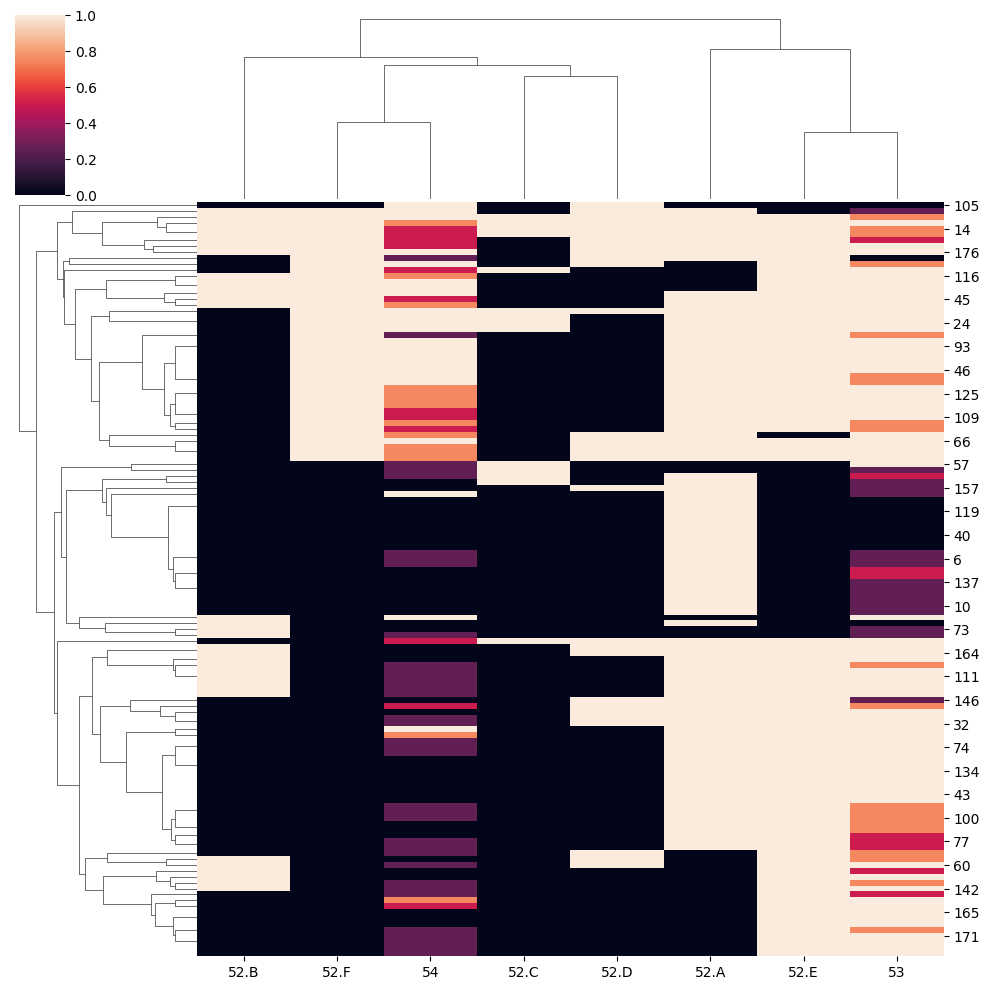

In [7]:
# Visualize data

sns.clustermap(survey_answers_learning_strategies)

In [8]:
# Train Test split to prevent daka leakage (80% train, 20% test)
X = survey_answers_learning_strategies

X_train, X_test = train_test_split(
X,  test_size=0.2, random_state=42)

In [9]:
# Data is categorical and discrete so MCA will be used before putting into a GMM
mca = prince.MCA(
    n_components=8,
    engine='sklearn',
    random_state=42,
    one_hot=False, # one hot encoding is done
    check_input=True,
    copy=True)
mca = mca.fit(X_train)
X_train = mca.row_coordinates(X_train)
X_test = mca.row_coordinates(X_test)

In [10]:
mca.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.239,24.74%,24.74%
1,0.225,23.30%,48.04%
2,0.179,18.52%,66.56%
3,0.151,15.58%,82.14%
4,0.118,12.20%,94.33%
5,0.041,4.26%,98.59%
6,0.014,1.41%,100.00%


In [11]:
X_test.head()

,0,1,2,3,4,5,6
77,-0.407342,-0.395400,-0.163538,0.049056,0.241635,0.035090,-0.298441
56,-0.454950,-0.358201,-0.266003,0.068694,0.413710,-0.123691,0.050613
26,-0.800196,-1.176765,0.740508,1.085735,-0.127721,0.013765,-0.174867
42,0.420895,0.094287,0.403965,-0.790311,-0.055510,0.006307,0.002833
134,-0.454950,-0.358201,-0.266003,0.068694,0.413710,-0.123691,0.050613


In [12]:
# X_train = X_train.iloc[:,:4]
# X_test = X_test.iloc[:,:4]

In [13]:
X_test.head()

,0,1,2,3,4,5,6
77,-0.407342,-0.395400,-0.163538,0.049056,0.241635,0.035090,-0.298441
56,-0.454950,-0.358201,-0.266003,0.068694,0.413710,-0.123691,0.050613
26,-0.800196,-1.176765,0.740508,1.085735,-0.127721,0.013765,-0.174867
42,0.420895,0.094287,0.403965,-0.790311,-0.055510,0.006307,0.002833
134,-0.454950,-0.358201,-0.266003,0.068694,0.413710,-0.123691,0.050613


In [14]:
X_train.head()

,0,1,2,3,4,5,6
100,-0.393084,-0.360496,-0.211322,0.025732,0.275317,0.051971,-0.137325
108,3.088603,-0.310543,-1.039005,1.762355,0.476450,0.228807,-0.112618
66,0.189999,-0.120506,0.412518,-0.454325,-0.038323,0.017190,0.041221
0,1.097164,-0.130613,-0.623988,0.165660,-0.115078,-0.260984,0.026621
18,-0.282327,0.051081,-0.769259,-0.439826,0.684425,-0.192418,0.163353


In [15]:
mca.plot(
    X,
    x_component=0,
    y_component=1,
    show_column_markers=True,
    show_row_markers=True,
    show_column_labels=False,
    show_row_labels=False,
)

alt.LayerChart(...)

In [16]:
mca.column_contributions_.style.format("{:.0%}")

,0,1,2,3,4,5,6
52.A,13%,29%,11%,25%,0%,0%,1%
52.B,3%,68%,1%,17%,3%,0%,0%
52.C,63%,1%,6%,25%,2%,0%,1%
52.D,9%,2%,57%,9%,16%,0%,0%
52.E,2%,0%,13%,9%,11%,8%,36%
52.F,5%,0%,0%,8%,47%,27%,3%
53,1%,0%,11%,1%,9%,1%,56%
54,3%,0%,0%,6%,12%,63%,4%


In [17]:
gm = GaussianMixture(n_components=5,random_state=42).fit(X_train)

  File "C:\Users\hakan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [18]:
gm.means_

array([[ 0.18238404, -0.05238718,  0.02686918, -0.12327714, -0.23468501,
        -0.06505092,  0.00503485],
       [-0.56798029,  1.75866634,  0.25918028,  1.08707926, -0.39037386,
         0.10512501,  0.0490635 ],
       [-0.70923362, -1.001039  ,  0.53110651,  0.8869105 , -0.03272179,
         0.07002575,  0.06551464],
       [-0.25375633,  0.08941282, -0.15769819, -0.09295973,  0.33354957,
         0.07755067, -0.02322637],
       [ 2.53446186, -0.25487707, -0.98866039,  1.43015766,  0.50467699,
         0.2302844 ,  0.17864331]])

In [19]:
# Testing using the BIC (choose lowest)
components = range(1,7)

models = [] # List of fitted models
for n in components:
    gm = GaussianMixture(n_components=n,random_state=42).fit(X_train)
    print(f'components:{n}\n\tBIC:{gm.bic(X_test):.2f}\n\tAIC:{gm.aic(X_test):.2f}')
    models.append(gm)
"""
Both methods clearly agree on using 3 components
"""

components:1
	BIC:256.32
	AIC:212.28
components:2
	BIC:877.60
	AIC:788.28
components:3
	BIC:17.19
	AIC:-117.42
components:4
	BIC:129.23
	AIC:-50.68
components:5
	BIC:308.61
	AIC:83.41
components:6
	BIC:1596125.18
	AIC:1595854.69


'\nBoth methods clearly agree on using 3 components\n'

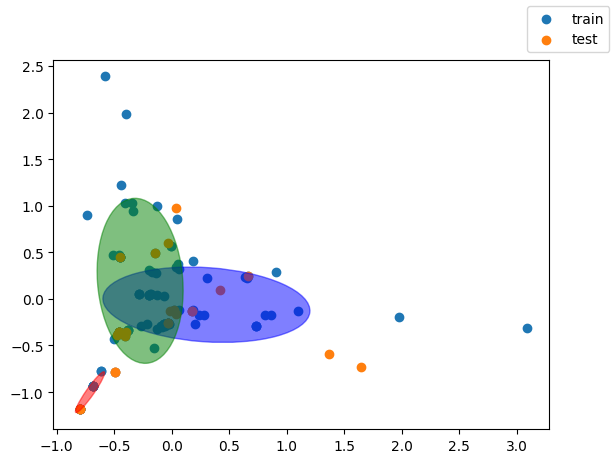

In [20]:
chosen_component = 3
chosen_model = models[chosen_component - 1]

colors = ['blue','green','red',"purple","grey"]
fig,ax = plt.subplots()
ax.scatter(X_train.iloc[:,0],X_train.iloc[:,1],label='train')
ax.scatter(X_test.iloc[:,0],X_test.iloc[:,1],label='test')

for n in range(chosen_component):
    mean = chosen_model.means_[n,:2]
    covariance = chosen_model.covariances_[n][:2,:2]
    
    v,w = linalg.eigh(covariance)
    
    angle = np.arctan2(w[0][1],w[0][0])
    angle = 180.0 * angle / np.pi
    v = 2.0 * np.sqrt(2.0) * np.sqrt(v)
    # covariance = 
    ellipse = Ellipse(mean,v[0],v[1],angle = 180.0 + angle,color=colors[n])
    ellipse.set_clip_box(fig.bbox)
    ellipse.set_alpha(0.5)
    ax.add_patch(ellipse)
    
    
fig.legend()
fig.show()

In [21]:
#  TO do: add correlation matrix